In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

In [2]:
import urllib.request

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
urllib.request.urlretrieve(url, "train.csv")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [3]:
# Step 2: Load and inspect data
df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)
print(df.head())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSurvival distribution:\n", df["Survived"].value_counts())

Dataset shape: (891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8

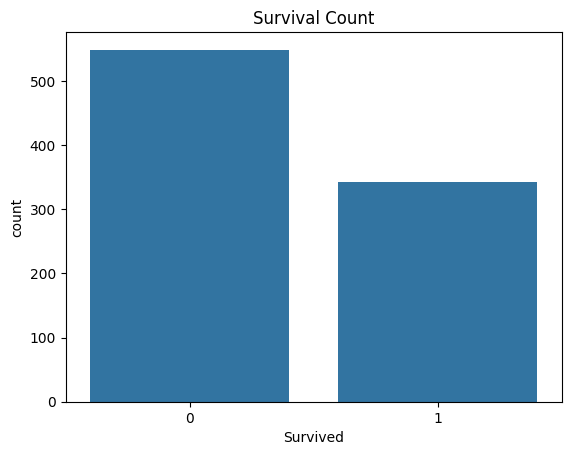

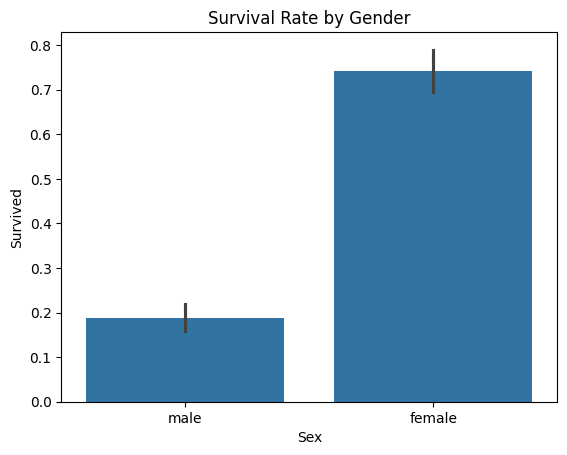

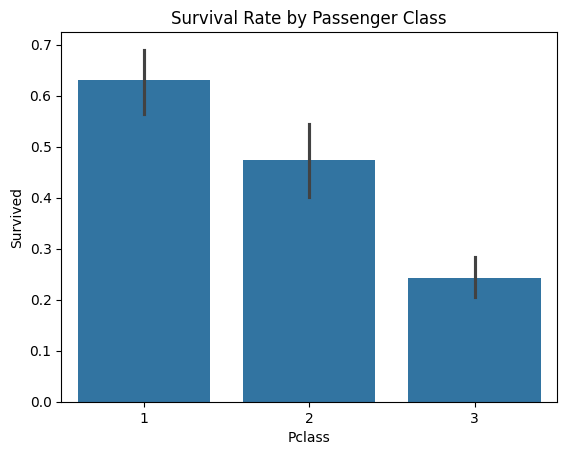

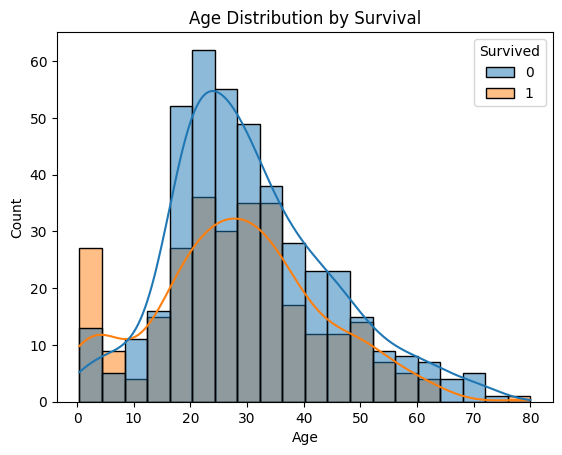

In [4]:
# Step 3: Visualize survival count
sns.countplot(data=df, x="Survived")
plt.title("Survival Count")
plt.savefig("survival_count.png")
plt.show()

# Survival rate by gender
sns.barplot(data=df, x="Sex", y="Survived")
plt.title("Survival Rate by Gender")
plt.savefig("survival_by_gender.png")
plt.show()

# Survival rate by passenger class
sns.barplot(data=df, x="Pclass", y="Survived")
plt.title("Survival Rate by Passenger Class")
plt.savefig("survival_by_class.png")
plt.show()

# Age distribution by survival
sns.histplot(data=df, x="Age", hue="Survived", bins=20, kde=True)
plt.title("Age Distribution by Survival")
plt.savefig("age_distribution.png")
plt.show()

In [5]:
# Step 4: Clean data and create useful features
df = df.drop_duplicates().copy()

df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.", expand=False)
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

X = df.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"])
y = df["Survived"]

num = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone"]
cat = ["Sex", "Embarked", "Title"]

print("Features:", X.columns.tolist())
print("Target distribution:\n", y.value_counts())

Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Title', 'FamilySize', 'IsAlone']
Target distribution:
 Survived
0    549
1    342
Name: count, dtype: int64


In [6]:
# Step 5: Split data and prepare preprocessing pipelines
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

prep = ColumnTransformer([
    ("num", num_pipe, num),
    ("cat", cat_pipe, cat)
])

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 712
Testing samples: 179


In [7]:
# Step 6: Train classification models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC()
}

for name in models:
    models[name] = Pipeline([("prep", prep), ("clf", models[name])])
    models[name].fit(X_train, y_train)

print("All five models trained successfully.")

All five models trained successfully.


In [8]:
# Step 7: Calculate classification metrics
results = []

for name, model in models.items():
    pred = model.predict(X_test)
    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0)
    ])

scores = pd.DataFrame(results, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1-score"
])

print(scores.round(3))
best_name = scores.loc[scores["F1-score"].idxmax(), "Model"]
best_model = models[best_name]
print("\nBest model based on F1-score:", best_name)

                 Model  Accuracy  Precision  Recall  F1-score
0  Logistic Regression     0.838      0.812   0.754     0.782
1        Decision Tree     0.793      0.808   0.609     0.694
2        Random Forest     0.804      0.750   0.739     0.745
3                  KNN     0.827      0.797   0.739     0.767
4                  SVM     0.844      0.825   0.754     0.788

Best model based on F1-score: SVM


Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.90      0.88       110
           1       0.83      0.75      0.79        69

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



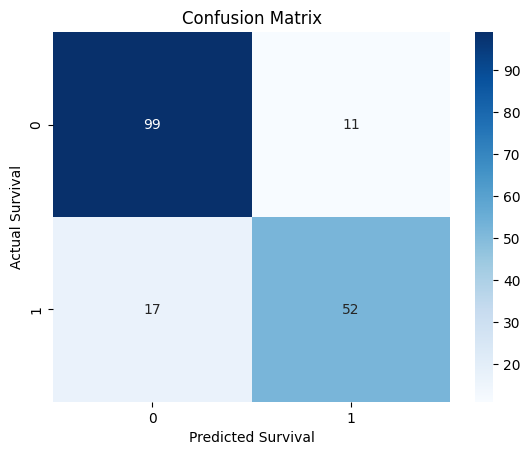

In [9]:
# Step 8: Evaluate the selected model
pred = best_model.predict(X_test)

print("Classification Report:\n")
print(classification_report(y_test, pred, zero_division=0))

sns.heatmap(confusion_matrix(y_test, pred), annot=True,
            fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Survival")
plt.ylabel("Actual Survival")
plt.savefig("confusion_matrix.png")
plt.show()

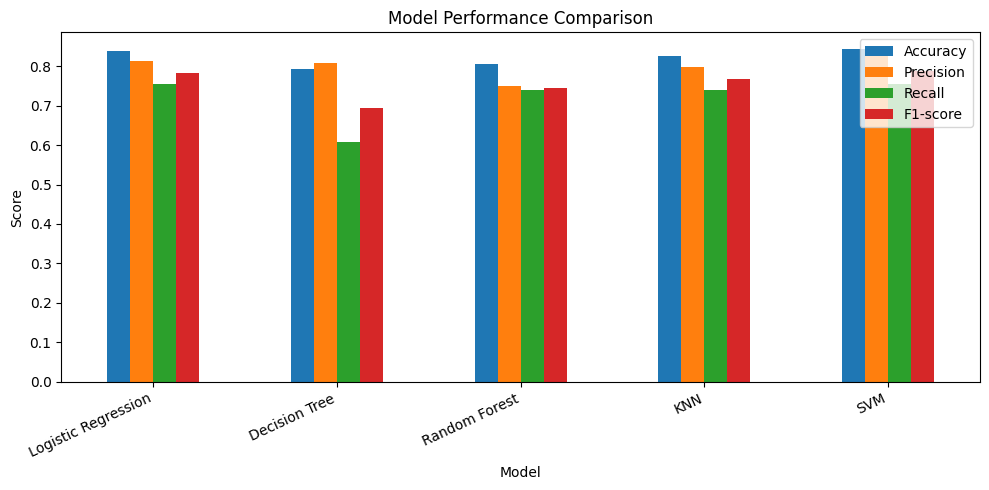

In [10]:
# Step 9: Compare model performance
scores.plot(x="Model", y=["Accuracy", "Precision", "Recall", "F1-score"],
            kind="bar", figsize=(10, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

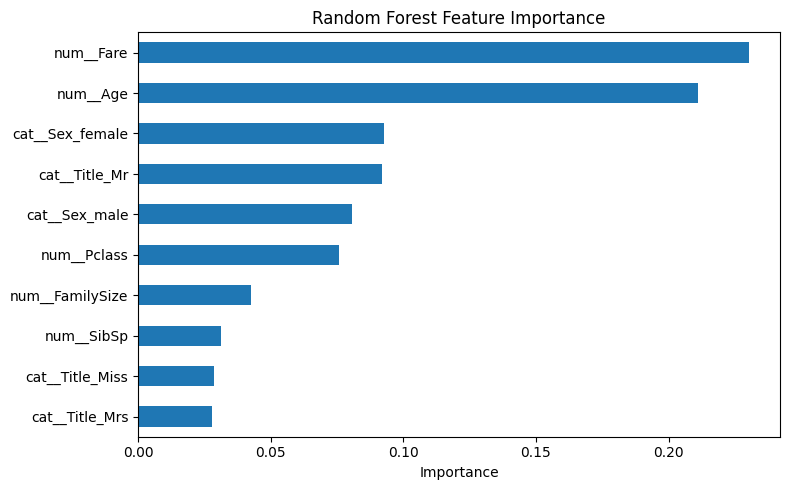

In [11]:
# Step 10: Identify important passenger features
rf = models["Random Forest"]
importance = rf.named_steps["clf"].feature_importances_
features = rf.named_steps["prep"].get_feature_names_out()

imp = pd.Series(importance, index=features).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

In [12]:
# Step 11: Predict survival for a sample passenger
sample = X_test.iloc[[0]]
prediction = best_model.predict(sample)[0]

print("Passenger details:\n", sample)
print("Predicted survival:", "Survived" if prediction == 1 else "Did not survive")
print("Actual survival:", "Survived" if y_test.iloc[0] == 1 else "Did not survive")

Passenger details:
      Pclass   Sex   Age  SibSp  Parch   Fare Embarked Title  FamilySize  \
565       3  male  24.0      2      0  24.15        S    Mr           3   

     IsAlone  
565        0  
Predicted survival: Did not survive
Actual survival: Did not survive
